# **Assignment 7**

**Dataset: UCI Human Activity Recognition (HAR) using Smartphones**
Link: https://archive.ics.uci.edu/dataset/240/human+activity+recognition+using+smartphones

Each sample is a **2.56 s window of smartphone sensor data**: 128 time steps x 9 channels (body acc x/y/z, body gyro x/y/z, total acc x/y/z). The task is to classify the activity into 6 classes: WALKING, WALKING_UPSTAIRS, WALKING_DOWNSTAIRS, SITTING, STANDING, LAYING.

Because this is **time-series** data, a 1D CNN (local temporal patterns), an RNN (long-range order) and a hybrid of the two are all natural choices, and you will compare them.

**Total: 20 marks**
**Submission:** a single `.ipynb` with outputs visible. Submit the model files (`.pth`) along with the notebook.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

# Set random seeds for reproducibility
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

# Configure the computation device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch version:", torch.__version__)
print("Device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.14.1+cu126
Device: cuda
GPU: NVIDIA GeForce GTX 1650


### Provided helper: dataset download and loading (run as is)

In [2]:
import os, zipfile, urllib.request                                      # filesystem, zip extraction, URL download

HAR_URL = "https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip"  # dataset download URL
SIGNALS = ['body_acc_x', 'body_acc_y', 'body_acc_z',                     # the 9 sensor channel name prefixes
           'body_gyro_x', 'body_gyro_y', 'body_gyro_z',
           'total_acc_x', 'total_acc_y', 'total_acc_z']
ACTIVITIES = ['WALKING', 'WALKING_UPSTAIRS', 'WALKING_DOWNSTAIRS', 'SITTING', 'STANDING', 'LAYING']  # the 6 class names

def download_har(root='./har'):                                         # download + unzip the HAR dataset if needed
    os.makedirs(root, exist_ok=True)                                    # create the target directory
    zpath = os.path.join(root, 'har.zip')                                # path to the downloaded zip
    if not os.path.exists(zpath):                                       # skip re-downloading if already present
        urllib.request.urlretrieve(HAR_URL, zpath)                      # fetch the zip from the UCI archive
    with zipfile.ZipFile(zpath) as z:                                    # open the outer zip
        z.extractall(root)                                               # extract its contents
    inner = os.path.join(root, 'UCI HAR Dataset.zip')       # the archive contains a nested zip  # path to the nested zip
    if os.path.exists(inner):                                            # only if the nested zip exists
        with zipfile.ZipFile(inner) as z:                                # open the nested zip
            z.extractall(root)                                           # extract it too
    return os.path.join(root, 'UCI HAR Dataset')                        # path to the usable dataset folder

def load_split(base, split):                                            # load one split ('train' or 'test') as arrays
    chans = [np.loadtxt(f"{base}/{split}/Inertial Signals/{s}_{split}.txt") for s in SIGNALS]  # load each of the 9 channel files
    X = np.stack(chans, axis=-1).astype(np.float32)          # (N, 128, 9)  # stack channels into (samples, timesteps, channels)
    y = np.loadtxt(f"{base}/{split}/y_{split}.txt", dtype=int) - 1   # labels 0..5  # load labels, shift from 1-indexed to 0-indexed
    return X, y                                                         # return features and labels

base = download_har()                                                    # ensure dataset is downloaded, get its folder path
X_tr, y_tr = load_split(base, 'train')                                  # load the official training split
X_te, y_te = load_split(base, 'test')                                   # load the official test split
print(X_tr.shape, y_tr.shape, X_te.shape, y_te.shape)       # expect (7352,128,9) (7352,) (2947,128,9) (2947,)  # sanity-check shapes

(7352, 128, 9) (7352,) (2947, 128, 9) (2947,)


### Q1 — Data loading, splitting and visualization [3 marks]

a. Load the UCI HAR dataset using the provided helper cell below, and **combine** the official train and test splits into one dataset. Print the shapes of `X` and `y`. [1 mark]

b. Standardize each of the 9 channels, then divide the dataset into training, validation and test sets (70%-15%-15%, stratified by activity label). Compute the mean/std on the **training set only**. [1 mark]

c. Plot the distribution of the activity labels on the training set (bar plot with class names). Plot one example window per activity class (9 channels, 6 subplots). [1 mark]

In [3]:
# 1a. Combine train + test
X = np.concatenate((X_tr, X_te), axis=0)
y = np.concatenate((y_tr, y_te), axis=0)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (10299, 128, 9)
y shape: (10299,)


In [4]:
# 1b. Standardize (train statistics only) and split 70-15-15 (stratified)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Stratified 70:15:15 split
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=RANDOM_SEED, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=RANDOM_SEED, stratify=y_temp)

# Convert to 2-D arrays
X_train_2d = X_train.reshape(-1, 9)
X_val_2d = X_val.reshape(-1, 9)
X_test_2d = X_test.reshape(-1, 9)

# Standardize features by fitting on training data
scaler = StandardScaler()
X_train_2d = scaler.fit_transform(X_train_2d)
X_val_2d = scaler.transform(X_val_2d)
X_test_2d = scaler.transform(X_test_2d)

# Recover the original shape
X_train = X_train_2d.reshape(-1, 128, 9)
X_val = X_val_2d.reshape(-1, 128, 9)
X_test = X_test_2d.reshape(-1, 128, 9)

print(f"Training data: X = {X_train.shape}, y = {y_train.shape}")
print(f"Validation data: X = {X_val.shape}, y = {y_val.shape}")
print(f"Testing data: X = {X_test.shape}, y = {y_test.shape}")

Training data: X = (7209, 128, 9), y = (7209,)
Validation data: X = (1545, 128, 9), y = (1545,)
Testing data: X = (1545, 128, 9), y = (1545,)


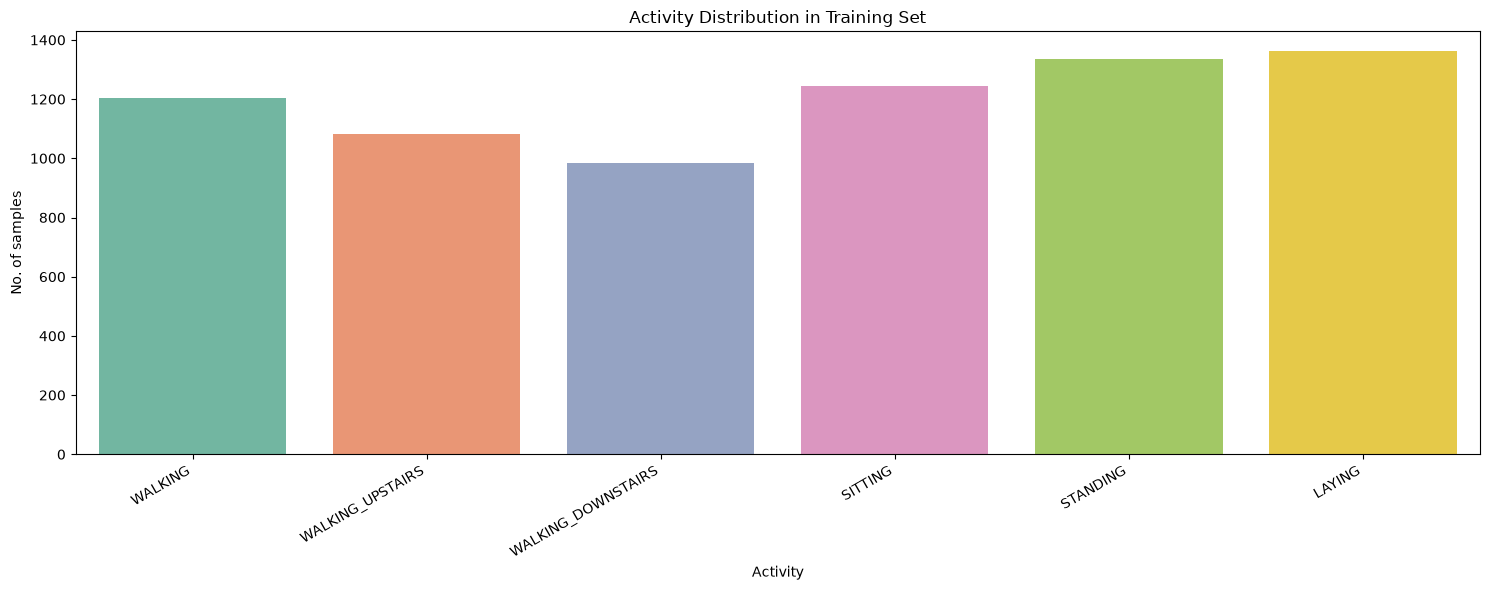

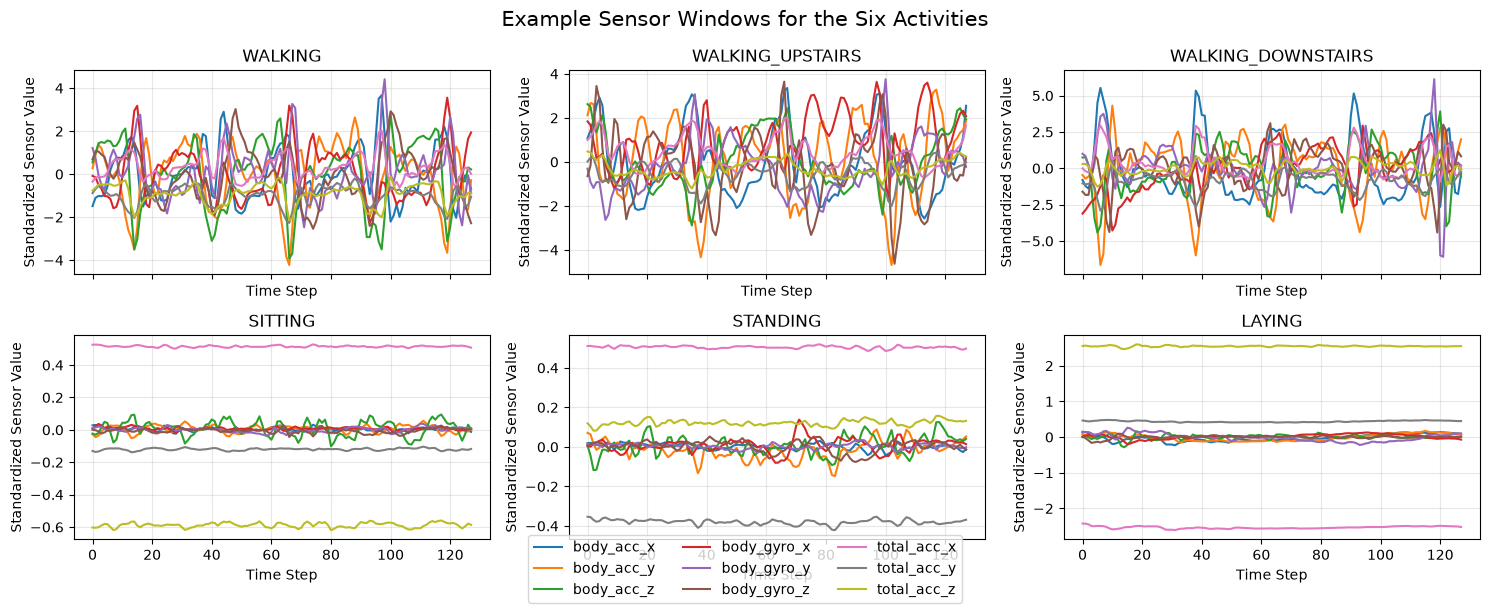

In [5]:
# 1c. Plot label distribution + one example window per activity

# Plot the distribution of activity labels in the training set
plt.figure(figsize=(15, 6))
counts = np.bincount(y_train, minlength=len(ACTIVITIES))
df_counts = pd.DataFrame({"Activity": ACTIVITIES, "No. of samples": counts})
sns.barplot(data=df_counts, x="Activity", y="No. of samples", hue="Activity", palette="Set2", legend=False)
plt.title("Activity Distribution in Training Set")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig("plots/activity_dist.png")

# Plot one example window per activity class
fig, axes = plt.subplots(2, 3, figsize=(15, 6), sharex=True)
time_steps = np.arange(128)

for activity_id, ax in enumerate(axes.flat):
    # Find the first training sample belonging to this activity
    sample_idx = np.where(y_train == activity_id)[0][0]

    # Plot all nine sensor channels
    for channel_id, channel_name in enumerate(SIGNALS):
        ax.plot(time_steps, X_train[sample_idx, :, channel_id], label=channel_name)

    ax.set_title(ACTIVITIES[activity_id])
    ax.set_xlabel("Time Step")
    ax.set_ylabel("Standardized Sensor Value")
    ax.grid(True, alpha=0.3)

# Add a shared legend for all nine channels
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.02))
fig.suptitle("Example Sensor Windows for the Six Activities", fontsize=15)
plt.tight_layout()
plt.savefig("plots/example_signals.png")

### Q2 — Model design [8 marks]

a. Using PyTorch, design a **1D CNN** (`nn.Conv1d`) for activity classification. Use ReLU activation and `MaxPool1d` after every 2 conv layers, following the `SimpleCNN` structure from the demo. Note that `Conv1d` expects input of shape `(batch, channels, time)`. [2 marks]

b. Design a **recurrent model** using `nn.GRU` or `nn.LSTM` (bidirectional optional) that classifies from the final hidden state. [2 marks]

c. Design a **hybrid CNN-LSTM**: Conv1d layers extract local features and downsample the sequence, and the LSTM then models the resulting shorter sequence. Experiment with varying depth, number of filters and hidden size to achieve better performance. [2 marks]

d. Design a **joint (multi-task) loss** for the CNN-LSTM. Add a second output head that predicts whether the activity is **static** (SITTING, STANDING, LAYING) or **dynamic** (the three walking classes). Combine the two losses as $\mathcal{L} = \mathcal{L}_{CE} + \lambda\,\mathcal{L}_{BCE}$. Justify your choice of $\lambda$ using at least 3 values (e.g. 0, 0.5, 1). [2 marks]

In [6]:
# 2a. 1D CNN
class SimpleCNN(nn.Module):
    def __init__(self, n_classes=6):
        super().__init__()                              # (Batch, channel, time_step)
        self.conv1 = nn.Conv1d(9, 16, 3, padding=1)     # (B, 9, 128) -> (B, 16, 128): 9 channels -> 16 feature maps
        self.conv2 = nn.Conv1d(16, 32, 3, padding=1)    # (B, 16, 128) -> (B, 32, 128): 16 -> 32 feature maps
        self.conv3 = nn.Conv1d(32, 64, 3, padding=1)    # (B, 32, 64) -> (B, 64, 64): 32 -> 64 feature maps
        self.conv4 = nn.Conv1d(64, 128, 3, padding=1)   # (B, 64, 64) -> (B, 128, 64): 64 -> 128 feature maps
        self.pool = nn.MaxPool1d(2, 2)                  # Halves the time steps
        self.dropout = nn.Dropout(0.5)                  # Randomly zeros 50% of activations during training (regularization)
        self.fc1 = nn.Linear(128 * 32, 128)             # Flatten (B, 128, 32) -> (B, 4096) -> (B, 128)
        self.fc2 = nn.Linear(128, n_classes)            # (B, 128) -> (B, n_classes): one logit per activity
        
    def forward(self, x):
        x = x.transpose(1, 2)                           # x = (Batch, time_step, channel)
        x = F.relu(self.conv1(x))                       # Conv1 + ReLU
        x = self.pool(F.relu(self.conv2(x)))            # Conv2 + ReLU + MaxPool1d
        x = F.relu(self.conv3(x))                       # Conv3 + ReLU
        x = self.pool(F.relu(self.conv4(x)))            # Conv4 + ReLU + MaxPool1d
        x = x.flatten(1)                                # Preserve batch, flatten features
        x = self.dropout(F.relu(self.fc1(x)))           # FC1 + ReLU + Dropout
        return self.fc2(x)                              # Raw class logits from FC2

In [7]:
# 2b. GRU / LSTM model
class SeqRNN(nn.Module):
    def __init__(self, rnn_type, input_size=9, hidden_size=128, n_layers=2, n_classes=6, dropout=0.3):
        super().__init__()
        rnn_class = {"rnn": nn.RNN, "gru": nn.GRU, "lstm": nn.LSTM}[rnn_type]
        self.rnn = rnn_class(input_size, hidden_size, n_layers, batch_first=True, dropout=dropout)  # Input: (B, 128, 9)
        self.fc = nn.Linear(hidden_size, n_classes)                                                 # Final hidden state: (B, 128) -> (B, 6)
        
    def forward(self, x):
        out, hidden = self.rnn(x)                                       # out: (B, 128, 128); hidden: (2, B, 128)
        h_n = hidden[0] if isinstance(hidden, tuple) else hidden        # LSTM returns (h_n, c_n); RNN/GRU return h_n
        return self.fc(h_n[-1])                                         # Last recurrent layer's final hidden state: (B, 128) -> (B, 6)

In [8]:
# 2c. Hybrid CNN-LSTM
class HybridCNNLSTM(nn.Module):
    def __init__(self, n_classes=6, hidden_size=128, n_layers=2):
        super().__init__()
        self.cnn = nn.Sequential(
            nn.Conv1d(9, 16, kernel_size=3, padding=1),     # (B, 9, 128) -> (B, 16, 128)
            nn.ReLU(),
            nn.Conv1d(16, 32, kernel_size=3, padding=1),    # (B, 16, 128) -> (B, 32, 128)
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2, stride=2),          # (B, 32, 128) -> (B, 32, 64)
            nn.Conv1d(32, 64, kernel_size=3, padding=1),    # (B, 32, 64) -> (B, 64, 64)
            nn.ReLU(),
            nn.Conv1d(64, 128, kernel_size=3, padding=1),   # (B, 64, 64) -> (B, 128, 64)
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2, stride=2),          # (B, 128, 64) -> (B, 128, 32)
        )
        self.lstm = nn.LSTM(
            input_size=128, hidden_size=hidden_size, num_layers=n_layers, batch_first=True, dropout=0.3 if n_layers > 1 else 0
        )
        self.fc = nn.Linear(hidden_size, n_classes)         # (B, 128) -> (B, 6)
        
    def forward(self, x):
        x = x.transpose(1, 2)         # (B, 128, 9) -> (B, 9, 128)
        x = self.cnn(x)               # (B, 9, 128) -> (B, 128, 32)
        x = x.transpose(1, 2)         # (B, 128, 32) -> (B, 32, 128)
        _, (h_n, c_n) = self.lstm(x)  # h_n: (n_layers, B, hidden_size)
        x = h_n[-1]                   # (B, hidden_size)
        return self.fc(x)             # (B, hidden_size) -> (B, n_classes)

In [9]:
# 2d. Multi-task CNN-LSTM (two heads) and joint loss
class MultiTaskHybridCNNLSTM(nn.Module):
    def __init__(self, n_classes=6, hidden_size=128, n_layers=2):
        super().__init__()
        self.cnn = nn.Sequential(
            nn.Conv1d(9, 16, kernel_size=3, padding=1),     # (B, 9, 128) -> (B, 16, 128)
            nn.ReLU(),
            nn.Conv1d(16, 32, kernel_size=3, padding=1),    # (B, 16, 128) -> (B, 32, 128)
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2, stride=2),          # (B, 32, 128) -> (B, 32, 64)
            nn.Conv1d(32, 64, kernel_size=3, padding=1),    # (B, 32, 64) -> (B, 64, 64)
            nn.ReLU(),
            nn.Conv1d(64, 128, kernel_size=3, padding=1),   # (B, 64, 64) -> (B, 128, 64)
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2, stride=2),          # (B, 128, 64) -> (B, 128, 32)
        )
        self.lstm = nn.LSTM(
            input_size=128, hidden_size=hidden_size, num_layers=n_layers, batch_first=True, dropout=0.3 if n_layers > 1 else 0
        )
        self.activity_head = nn.Linear(hidden_size, n_classes)          # Six activity classes
        self.static_head = nn.Linear(hidden_size, 1)                    # Static vs dynamic
        
    def forward(self, x):
        x = x.transpose(1, 2)         # (B, 128, 9) -> (B, 9, 128)
        x = self.cnn(x)               # (B, 9, 128) -> (B, 128, 32)
        x = x.transpose(1, 2)         # (B, 128, 32) -> (B, 32, 128)
        _, (h_n, c_n) = self.lstm(x)  # h_n: (n_layers, B, hidden_size)
        features = h_n[-1]            # (B, hidden_size)
        
        activity_logits = self.activity_head(features)      # (B, 6)
        static_logits = self.static_head(features)          # (B, 1)
        return activity_logits, static_logits
        
        
def joint_loss(activity_logits, static_logits, y_activity, y_static, lambda_val=0.5):
    """
    Joint loss = L_CE + lambda * L_BCE
    y_activity  : integer class labels (0 to 5)
    y_static    : binary labels, where 1 = static and 0 = dynamic
    """
    loss_ce = F.cross_entropy(activity_logits, y_activity)
    loss_bce = F.binary_cross_entropy_with_logits(static_logits.squeeze(1), y_static.float())
    loss = loss_ce + lambda_val * loss_bce
    return loss, loss_ce, loss_bce

**Choice of Lambda \($\lambda$\) in the Joint-loss function**

By default, we set $\lambda = 0.5$ to give the auxiliary static/dynamic classification task a moderate contribution while prioritizing six-class activity recognition. If $\lambda = 0$, the auxiliary loss is ignored, and the model learns only from the six-class classification task. If $\lambda = 1$, both losses receive equal nominal weight, giving the auxiliary task a much stronger influence on shared feature learning.

### Q3 — Training [4 marks]

a. Train all models using SGD with an appropriate minibatch size and learning rate (momentum and gradient clipping are allowed). Record the training and validation loss after every epoch. Save the best checkpoint of each model (lowest validation loss). [3 marks]

b. Plot the training and validation losses for each model. [1 mark]

In [16]:
# 3a. Training loop (SGD), record losses, save best checkpoints
import time
import copy

# Convert numpy arrays into pytorch tensors
X_train = torch.tensor(X_train, dtype=torch.float32)
y_train = torch.tensor(y_train, dtype=torch.long)
X_val = torch.tensor(X_val, dtype=torch.float32)
y_val = torch.tensor(y_val, dtype=torch.long)

# Create binary labels (static = 1, dynamic = 0)
y_train_static = (y_train >= 3).float()
y_val_static = (y_val >= 3).float()

# Create mini-batch loader
batch_size = 64
train_loader = DataLoader(TensorDataset(X_train, y_train, y_train_static), batch_size=batch_size, shuffle=True)
val_loader = DataLoader(TensorDataset(X_val, y_val, y_val_static), batch_size=batch_size, shuffle=False)

# Initialize all models
models = {
    "SimpleCNN": SimpleCNN(n_classes=6),
    "GRU": SeqRNN("gru", n_classes=6),
    "HybridCNNLSTM": HybridCNNLSTM(n_classes=6),
    "MultiTaskCNNLSTM": MultiTaskHybridCNNLSTM(n_classes=6)
}

# Training hyperparams
epochs = 50
learning_rate = 0.01
momentum = 0.9
lambda_val = 0.5
history = {}                # Loss history of each model
training_times = {}         # store training time

# Iterate over all models
for name, model in models.items():
    model = model.to(device)
    optimizer = optim.SGD(model.parameters(), lr=learning_rate, momentum=momentum)
    
    best_state = None
    best_val_loss = float("inf")
    history[name] = {"train_loss": [], "val_loss": []}
    start_time = time.time()
    
    # Iterate over each epoch
    for epoch in range(epochs):
        # Training
        model.train()
        train_loss_sum = 0.0
        train_count = 0
        
        # Iterate over training mini-batches
        for xb, yb, yb_static in train_loader:
            xb, yb, yb_static = xb.to(device), yb.to(device), yb_static.to(device)
            optimizer.zero_grad()   # clear accumulated gradients
            
            if name == "MultiTaskCNNLSTM":
                activity_logits, static_logits = model(xb)
                loss, _, _ = joint_loss(activity_logits, static_logits, yb, yb_static, lambda_val)
            else:
                logits = model(xb)
                loss = F.cross_entropy(logits, yb)
                
            loss.backward()         # backpropagate
            optimizer.step()        # parameter update
            
            train_loss_sum += loss.item() * xb.size(0)
            train_count += xb.size(0)
        
        train_loss = train_loss_sum / train_count
        
        # Validation
        model.eval()
        val_loss_sum = 0.0
        val_count = 0

        # Disable gradient computation & iterate over validation mini-batches
        with torch.no_grad():
            for xb, yb, yb_static in val_loader:
                xb, yb, yb_static = xb.to(device), yb.to(device), yb_static.to(device)

                if name == "MultiTaskCNNLSTM":
                    activity_logits, static_logits = model(xb)
                    loss, _, _ = joint_loss(activity_logits, static_logits, yb, yb_static, lambda_val)
                else:
                    logits = model(xb)
                    loss = F.cross_entropy(logits, yb)

                val_loss_sum += loss.item() * xb.size(0)
                val_count += xb.size(0)

        val_loss = val_loss_sum / val_count
        
        # Record losses after each epoch
        history[name]["train_loss"].append(train_loss)
        history[name]["val_loss"].append(val_loss)
        
        # Save checkpoint with the lowest validation error
        if val_loss < best_val_loss:
            best_state = copy.deepcopy(model.state_dict())
            torch.save(best_state, f"best_checkpoints/{name}.pth")
            best_val_loss = val_loss
            
        print(f"{name} | Epoch {(epoch + 1):2d}/{epochs} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}")
        
    # Restore the best checkpoint
    model.load_state_dict(best_state)
    models[name] = model
    training_times[name] = time.time() - start_time
    print(f"{name} | Best Val Loss: {best_val_loss:.4f} | Time: {training_times[name]:.2f}s\n")
    

C:\Users\SWARNOTAJ\AppData\Local\Temp\ipykernel_20652\2937982636.py:6: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  X_train = torch.tensor(X_train, dtype=torch.float32)
C:\Users\SWARNOTAJ\AppData\Local\Temp\ipykernel_20652\2937982636.py:7: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_train = torch.tensor(y_train, dtype=torch.long)
C:\Users\SWARNOTAJ\AppData\Local\Temp\ipykernel_20652\2937982636.py:8: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  X_val = torch.tensor(X_val, dtype=torch.float32)
C:\Users\SWARNOTAJ\AppData\Local\Temp\ipy

SimpleCNN | Epoch  1/50 | Train Loss: 1.3173 | Val Loss: 0.7204
SimpleCNN | Epoch  2/50 | Train Loss: 0.5707 | Val Loss: 0.3826
SimpleCNN | Epoch  3/50 | Train Loss: 0.3089 | Val Loss: 0.1954
SimpleCNN | Epoch  4/50 | Train Loss: 0.2172 | Val Loss: 0.1850
SimpleCNN | Epoch  5/50 | Train Loss: 0.2072 | Val Loss: 0.1262
SimpleCNN | Epoch  6/50 | Train Loss: 0.1539 | Val Loss: 0.1242
SimpleCNN | Epoch  7/50 | Train Loss: 0.1511 | Val Loss: 0.1443
SimpleCNN | Epoch  8/50 | Train Loss: 0.1478 | Val Loss: 0.1096
SimpleCNN | Epoch  9/50 | Train Loss: 0.1494 | Val Loss: 0.1112
SimpleCNN | Epoch 10/50 | Train Loss: 0.1356 | Val Loss: 0.1217
SimpleCNN | Epoch 11/50 | Train Loss: 0.1306 | Val Loss: 0.1185
SimpleCNN | Epoch 12/50 | Train Loss: 0.1341 | Val Loss: 0.1008
SimpleCNN | Epoch 13/50 | Train Loss: 0.1241 | Val Loss: 0.1158
SimpleCNN | Epoch 14/50 | Train Loss: 0.1155 | Val Loss: 0.1214
SimpleCNN | Epoch 15/50 | Train Loss: 0.1222 | Val Loss: 0.1314
SimpleCNN | Epoch 16/50 | Train Loss: 0.

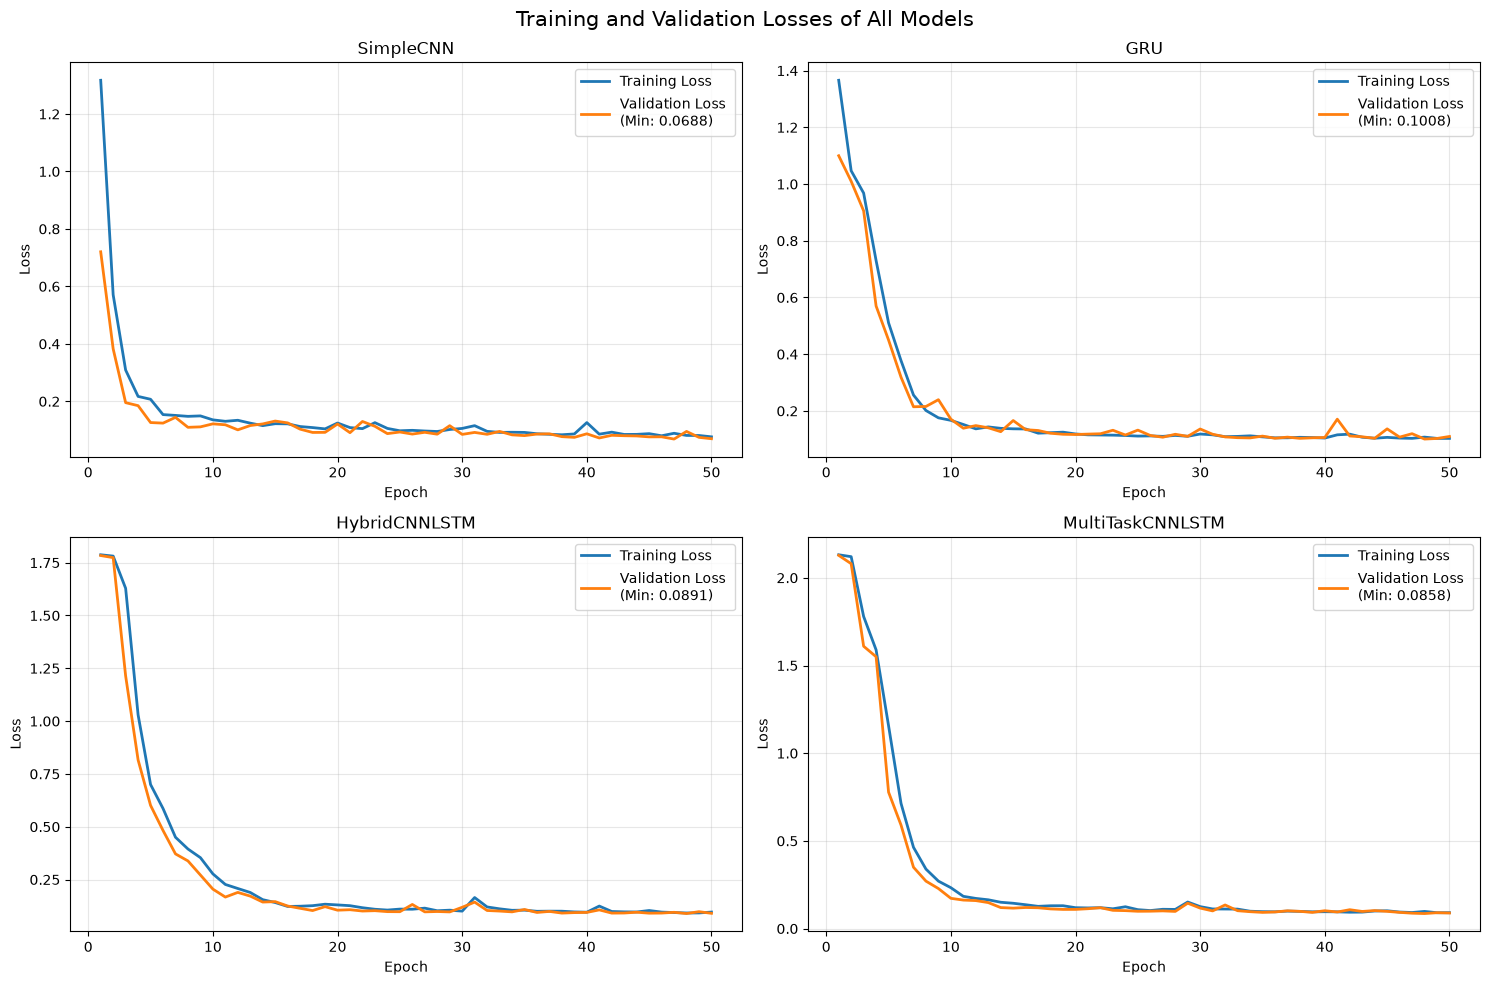

In [17]:
# 3b. Plot training / validation losses
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

for ax, (name, losses) in zip(axes.flat, history.items()):
    epochs_range = range(1, len(losses["train_loss"]) + 1)
    lowest_val_loss = min(losses["val_loss"])
    
    ax.plot(epochs_range, losses["train_loss"], label="Training Loss", linewidth=2)
    ax.plot(epochs_range, losses["val_loss"], label=f"Validation Loss \n(Min: {lowest_val_loss:.4f})", linewidth=2)

    ax.set_title(name)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.legend()
    ax.grid(True, alpha=0.3)

fig.suptitle("Training and Validation Losses of All Models", fontsize=15)
plt.tight_layout()
plt.savefig("plots/loss_curves.png")

### Q4 — Evaluation [5 marks]

a. Load the saved models and evaluate them on the test set. For each model report: classification report (accuracy, precision, recall, F1) and the confusion matrix. For the joint-loss model also report the accuracy of the static/dynamic head. [3 marks]

b. Prepare a comparison table (parameters, test accuracy, macro-F1, training time) for the three models and write a short discussion (4-5 lines): which model is best, which classes are most confused (e.g. SITTING vs STANDING) and why, and what the recurrent component adds over a pure CNN. [2 marks]

Model: SimpleCNN
Test Accuracy: 0.9599

Classification Report:
                    precision    recall  f1-score   support

           WALKING     1.0000    0.9923    0.9961       259
  WALKING_UPSTAIRS     0.9914    0.9957    0.9935       231
WALKING_DOWNSTAIRS     0.9953    1.0000    0.9976       211
           SITTING     0.8741    0.9101    0.8917       267
          STANDING     0.9127    0.8776    0.8948       286
            LAYING     1.0000    1.0000    1.0000       291

          accuracy                         0.9599      1545
         macro avg     0.9622    0.9626    0.9623      1545
      weighted avg     0.9602    0.9599    0.9599      1545

Model: GRU
Test Accuracy: 0.9521

Classification Report:
                    precision    recall  f1-score   support

           WALKING     0.9962    1.0000    0.9981       259
  WALKING_UPSTAIRS     1.0000    1.0000    1.0000       231
WALKING_DOWNSTAIRS     1.0000    1.0000    1.0000       211
           SITTING     0.8440    0.8

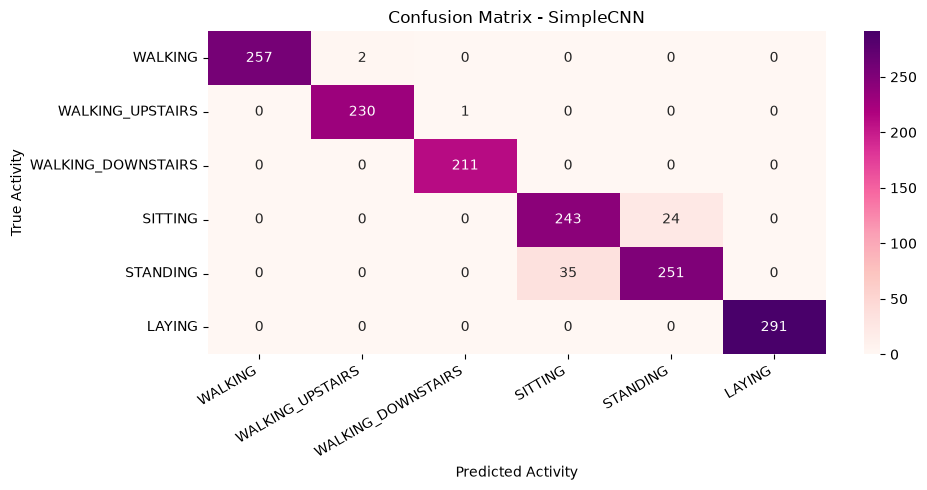

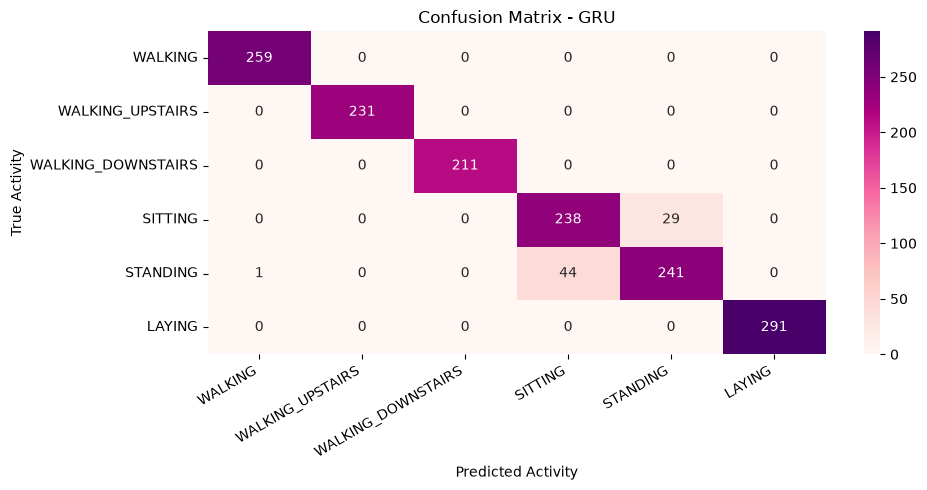

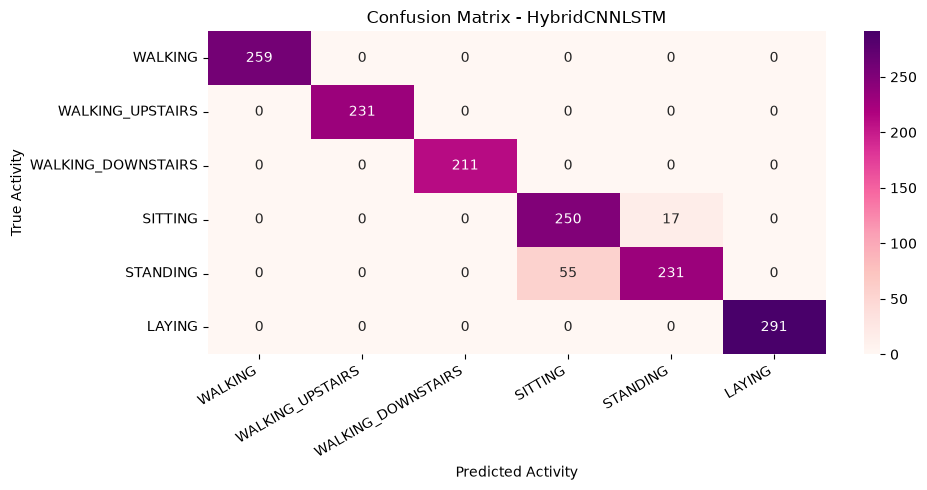

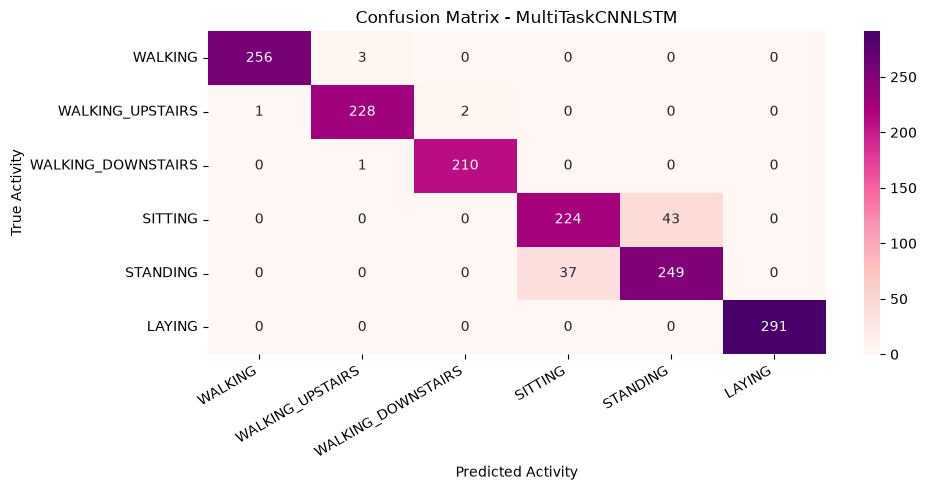

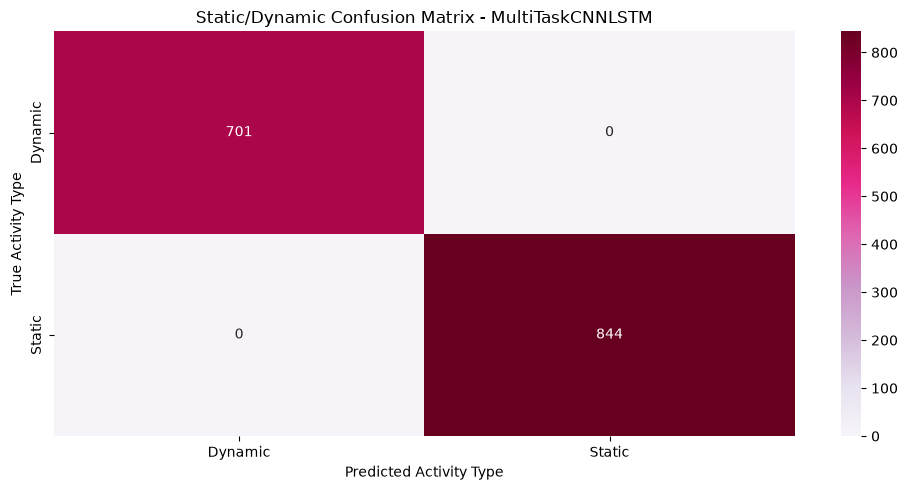

In [18]:
# 4a. Load models, classification report, confusion matrices, static/dynamic accuracy
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Convert test data into tensors
X_test_t = torch.as_tensor(X_test, dtype=torch.float32)
y_test_t = torch.as_tensor(y_test, dtype=torch.long)

# Create mini-batch loader
test_loader = DataLoader(TensorDataset(X_test_t, y_test_t), batch_size=batch_size, shuffle=False)

class_names = ACTIVITIES    # class labels
test_results = {}           # store evaluation metrics

# Evaluate each saved model
for name, model in models.items():
    checkpoint_path = f"best_checkpoints/{name}.pth"

    # Load the best validation-loss checkpoint
    model.load_state_dict(torch.load(checkpoint_path, map_location=device, weights_only=True))
    model = model.to(device)
    model.eval()

    y_true, y_pred = [], []
    y_static_true, y_static_pred = [], []

    # Disable gradient tracking & iterate over test mini-batches
    with torch.no_grad():
        for xb, yb in test_loader:
            xb = xb.to(device)

            if name == "MultiTaskCNNLSTM":
                activity_logits, static_logits = model(xb)
                predictions = activity_logits.argmax(dim=1)
                static_predictions = (static_logits.squeeze(1) >= 0).long()
                
                y_static_true.extend((yb >= 3).long().numpy())
                y_static_pred.extend(static_predictions.cpu().numpy())
            else:
                logits = model(xb)
                predictions = logits.argmax(dim=1)

            y_true.extend(yb.numpy())
            y_pred.extend(predictions.cpu().numpy())

    # Calculate activity-recognition metrics
    accuracy = accuracy_score(y_true, y_pred)
    report = classification_report(
        y_true, y_pred,
        labels=np.arange(len(class_names)),
        target_names=class_names,
        digits=4,
        zero_division=0
    )
    cm = confusion_matrix(y_true, y_pred, labels=np.arange(len(class_names)))
    test_results[name] = {
        "accuracy": accuracy,
        "confusion_matrix": cm
    }
    print(f"Model: {name}")
    print(f"Test Accuracy: {accuracy:.4f}")
    print("\nClassification Report:")
    print(report)

    # Plot confusion matrix
    plt.figure(figsize=(10, 5))
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="RdPu",
        xticklabels=class_names,
        yticklabels=class_names
    )
    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted Activity")
    plt.ylabel("True Activity")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.savefig(f"plots/confusion_matrix_{name}.png")

    # Evaluate the auxiliary static/dynamic head
    if name == "MultiTaskCNNLSTM":
        static_accuracy = accuracy_score(y_static_true, y_static_pred)
        print(f"Static/Dynamic Head Accuracy: {static_accuracy:.4f}")
        
        # Plot confusion matrix
        static_cm = confusion_matrix(y_static_true, y_static_pred, labels=[0, 1])
        plt.figure(figsize=(10, 5))
        sns.heatmap(
            static_cm, annot=True, fmt="d", cmap="PuRd",
            xticklabels=["Dynamic", "Static"],
            yticklabels=["Dynamic", "Static"]
        )
        plt.title("Static/Dynamic Confusion Matrix - MultiTaskCNNLSTM")
        plt.xlabel("Predicted Activity Type")
        plt.ylabel("True Activity Type")
        plt.tight_layout()
        plt.savefig(f"plots/confusion_matrix_static_labels.png")
        

In [20]:
# 4b. Comparison table + discussion
comparison = []

for name in ["SimpleCNN", "GRU", "HybridCNNLSTM", "MultiTaskCNNLSTM"]:
    model = models[name]
    cm = test_results[name]["confusion_matrix"]

    # Count trainable parameters
    n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

    # Calculate macro-F1 from the confusion matrix
    tp = np.diag(cm)
    precision = np.divide(
        tp, cm.sum(axis=0),
        out=np.zeros(len(tp), dtype=float),
        where=cm.sum(axis=0) != 0
    )
    recall = np.divide(
        tp, cm.sum(axis=1),
        out=np.zeros(len(tp), dtype=float),
        where=cm.sum(axis=1) != 0
    )
    f1 = np.divide(
        2 * precision * recall,
        precision + recall,
        out=np.zeros(len(tp), dtype=float),
        where=(precision + recall) != 0
    )

    comparison.append({
        "Model": name,
        "Trainable Parameters": n_params,
        "Test Accuracy": test_results[name]["accuracy"],
        "Macro-F1": f1.mean(),
        "Training Time (s)": training_times[name]
    })

comparison_df = pd.DataFrame(comparison)

display(comparison_df.style.format({
    "Test Accuracy": "{:.4f}",
    "Macro-F1": "{:.4f}",
    "Training Time (s)": "{:.2f}"
}))

,Model,Trainable Parameters,Test Accuracy,Macro-F1,Training Time (s)
0,SimpleCNN,558118,0.9599,0.9623,76.51
1,GRU,153222,0.9521,0.9553,98.06
2,HybridCNNLSTM,297894,0.9534,0.9565,113.27
3,MultiTaskCNNLSTM,298023,0.9437,0.9467,123.12


**Discussion (Q4b):** *write your answer here*

- The `SimpleCNN` performed best, achieving ***95.99% test accuracy and a macro-F1 score of 0.9623***, despite having the highest number of trainable parameters among the three single-task models. The `GRU` was the most parameter-efficient, with 153,222 parameters, while the HybridCNNLSTM took the longest to train among these three models. 
- `SITTING` and `STANDING` were the ***most confused classes***, as both involve ***relatively little movement and can produce similar accelerometer signals***, making them difficult to distinguish.
- The `recurrent component` in GRU and HybridCNNLSTM captures ***temporal dependencies across sensor sequences***, complementing the local patterns learned by CNN filters. However, in these experiments, the additional sequential modeling did not improve test performance enough to outperform the pure CNN.

---
End of the assignment